# Reproduce the two selected submissions

End-to-end inference on the 180 test H-alpha images, single image at a time, test labels never read:

1. **Detector** — YOLO11s-seg with a P2/stride-2 prototype head (`p2first`), trained on all 707 train files.
   4 flip views at 1024 px (box IoU 0.3, retina masks, agnostic NMS, score floor 0.1).
2. **Flip consensus** — views clustered at mask IoU 0.5; group score = sum of member scores / 4.
3. **Crop refiner** — ResNet18 U-Net on 256 px proposal-centred crops, 4-flip TTA, 7x7 seed clamp.
4. **refined_constrained** — threshold the refined probability, score-ordered pixel ownership (no overlaps), confidence cut 0.30.
5. *(V84 only)* drop masks < 200 px, then the LightGBM **demote** rule (28 per-candidate features, drop if ŷ ≤ λ/2).
6. COCO RLE → CSV → format/overlap validator.

| | V65 | V84 |
|---|---|---|
| refiner | `r3all_refiner_state.pt` | `soft_all_refiner_state.pt` |
| mask threshold | 0.45 | 0.50 |
| min area | 20 (cleaning floor) | 200 |
| demote | off | `demote_all.json` |

Settings via env vars: `SOLAR_TEST_DIR` (test images), `SOLAR_GPUS` (e.g. `"0 1 2"`), `SOLAR_OUT`.
Row order in the CSV follows the shard layout (image *i* goes to shard *i* mod *n*), so each run uses the shard
count of the original export (V65: 4, V84: 3); shards are spread round-robin over the GPUs given.

In [1]:
import hashlib, json, os, subprocess, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
from pycocotools import mask as mask_utils

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
TEST_DIR = Path(os.environ.get("SOLAR_TEST_DIR",
                "data/raw/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images"))
GPUS = os.environ.get("SOLAR_GPUS", "0")
OUT = Path(os.environ.get("SOLAR_OUT", "outputs/reproduce"))
OUT.mkdir(parents=True, exist_ok=True)
n_images = len(list(TEST_DIR.glob("*.jpeg")))
assert n_images == 180, f"expected 180 test images in {TEST_DIR}, found {n_images}"
print(ROOT, TEST_DIR, "GPUs:", GPUS)

~/solar-final ~/solar-filament-2026/data/raw/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images GPUs: 0 1 2


## 1. Verify the weights (SHA256SUMS)

In [2]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

for line in Path("weights/SHA256SUMS").read_text().splitlines():
    want, name = line.split()
    got = sha256(Path("weights") / name)
    assert got == want, f"{name}: {got} != {want}"
    print("ok", name, want[:12])

ok p2first_all707.pt 7ff392969bf2
ok r3all_refiner_state.pt 17b6280fe95f
ok soft_all_refiner_state.pt ef9e381038c9
ok demote_all.txt 4b8c23752282
ok demote_all.json 6c8a78634d74
ok training/best_refiner_coco.pt 8d0080531823


## 2. Run the export for both submissions

In [3]:
def export(name, shards, **env):
    t0 = time.monotonic()
    gpus = GPUS.split()
    e = dict(os.environ, PY=sys.executable, GPUS=" ".join(gpus[i % len(gpus)] for i in range(shards)),
             TEST_DIR=str(TEST_DIR), OUT=str(OUT), NAME=name, **env)
    r = subprocess.run(["bash", "scripts/export.sh"], env=e, capture_output=True, text=True)
    print(r.stdout[-1500:], r.stderr[-1500:])
    r.check_returncode()
    wall = time.monotonic() - t0
    mans = [json.loads(p.read_text()) for p in sorted((OUT / name).glob("shard_*.json"))]
    per_img = sum(m["seconds"] for m in mans) / sum(len(m["files"]) for m in mans)
    print(f"{name}: wall {wall:.0f}s for 180 images, {shards} shards on GPU(s) {GPUS}; "
          f"{per_img:.2f} s/image per GPU (detector+refiner, model load excluded)")
    return OUT / f"{name}.csv", wall, per_img

runs = {}
runs["v65"] = export("submission_v65", 4, MIN_AREA="20", MASK_T="0.45",
                     REFINER="weights/r3all_refiner_state.pt")

2026-10-12T03:08:02+00:00 submission_v65 detector weights/p2first_all707.pt 7ff392969bf26dd6ba30bc76360a583c256e7499892eb15ecdbce337b8174920 | refiner weights/r3all_refiner_state.pt 17b6280fe95fe9ac03a3769b6c2520bdf03318d54493795e6131bf0ef2849847 | imgsz 1024 min_area 20 mask_t 0.45 demote off
{
  "file": "outputs/reproduce/submission_v65.csv",
  "sha256": "530e89ea0f137757c6efc714c1a5878c2ff7e73bbb9a53e14815604b3b473c66",
  "rows": 1224,
  "populated_images": 177,
  "missing_images": [
    "20170708164010Mh",
    "20200310113230Ch",
    "20211214174010Mh"
  ],
  "median_instances_populated": 7.0,
  "min_mask_area": 22,
  "median_mask_area": 1266.0,
  "non_overlap": true,
  "full_rle_decode": true
}
2026-10-12T03:10:17+00:00 done: outputs/reproduce/submission_v65.csv 530e89ea0f137757c6efc714c1a5878c2ff7e73bbb9a53e14815604b3b473c66 (validated, NOT submitted)
 
submission_v65: wall 136s for 180 images, 4 shards on GPU(s) 0 1 2; 1.83 s/image per GPU (detector+refiner, model load excluded)

In [4]:
runs["v84"] = export("submission_v84", 3, MIN_AREA="200", MASK_T="0.50",
                     REFINER="weights/soft_all_refiner_state.pt", DEMOTE="weights/demote_all.json")

2026-10-12T03:10:17+00:00 submission_v84 detector weights/p2first_all707.pt 7ff392969bf26dd6ba30bc76360a583c256e7499892eb15ecdbce337b8174920 | refiner weights/soft_all_refiner_state.pt ef9e381038c9a24a7f01abc4744156c8390d6c7715068756f706f815129bcfe1 | imgsz 1024 min_area 200 mask_t 0.50 demote weights/demote_all.json
{
  "file": "outputs/reproduce/submission_v84.csv",
  "sha256": "2925e2a28cd789d500efc828be2858ea0edd7324ff98d09bd51e6c5295c4871f",
  "rows": 1112,
  "populated_images": 177,
  "missing_images": [
    "20170708164010Mh",
    "20200310113230Ch",
    "20211214174010Mh"
  ],
  "median_instances_populated": 6.0,
  "min_mask_area": 204,
  "median_mask_area": 1270.5,
  "non_overlap": true,
  "full_rle_decode": true
}
2026-10-12T03:13:35+00:00 done: outputs/reproduce/submission_v84.csv 2925e2a28cd789d500efc828be2858ea0edd7324ff98d09bd51e6c5295c4871f (validated, NOT submitted)
 
submission_v84: wall 198s for 180 images, 3 shards on GPU(s) 0 1 2; 2.48 s/image per GPU (detector+refi

## 3. Acceptance: compare with the CSVs that were submitted

Pass = identical SHA-256. Otherwise the per-mask IoU (matched by `filament_id`) is reported; tolerance IoU ≥ 0.999 for every mask and the same set of ids.

In [5]:
REFERENCE = {"v65": ("submissions/submission_v65_p2first_r3all.csv",
                     "530e89ea0f137757c6efc714c1a5878c2ff7e73bbb9a53e14815604b3b473c66", 1224),
             "v84": ("submissions/submission_v84.csv",
                     "2925e2a28cd789d500efc828be2858ea0edd7324ff98d09bd51e6c5295c4871f", 1112)}

def decode(s):
    return mask_utils.decode({"size": [2048, 2048], "counts": s.encode()})

summary = {}
for key, (csv, wall, per_img) in runs.items():
    ref, ref_sha, ref_rows = REFERENCE[key]
    assert sha256(ref) == ref_sha
    a, b = pd.read_csv(csv, dtype=str), pd.read_csv(ref, dtype=str)
    row = {"sha256": sha256(csv), "rows": len(a), "identical": sha256(csv) == ref_sha,
           "wall_s": round(wall), "s_per_image_per_gpu": round(per_img, 2)}
    if not row["identical"]:
        by_id = [d.sort_values("filament_id").reset_index(drop=True) for d in (a, b)]
        row["same_rows_any_order"] = by_id[0].equals(by_id[1])
        m = a.merge(b, on="filament_id", how="outer", suffixes=("_new", "_ref"))
        ious = [float(mask_utils.iou([{"size": [2048, 2048], "counts": x.encode()}],
                                     [{"size": [2048, 2048], "counts": y.encode()}], [0])[0, 0])
                if isinstance(x, str) and isinstance(y, str) else 0.0
                for x, y in zip(m.segmentation_rle_new, m.segmentation_rle_ref)]
        row.update(min_iou=min(ious), within_tolerance=min(ious) >= 0.999)
    summary[key] = row
print(json.dumps(summary, indent=2))
(OUT / "acceptance.json").write_text(json.dumps(summary, indent=2) + "\n")
assert all(r["identical"] or r["within_tolerance"] for r in summary.values())

{
  "v65": {
    "sha256": "530e89ea0f137757c6efc714c1a5878c2ff7e73bbb9a53e14815604b3b473c66",
    "rows": 1224,
    "identical": true,
    "wall_s": 136,
    "s_per_image_per_gpu": 1.83
  },
  "v84": {
    "sha256": "2925e2a28cd789d500efc828be2858ea0edd7324ff98d09bd51e6c5295c4871f",
    "rows": 1112,
    "identical": true,
    "wall_s": 198,
    "s_per_image_per_gpu": 2.48
  }
}


## 4. Look at one prediction

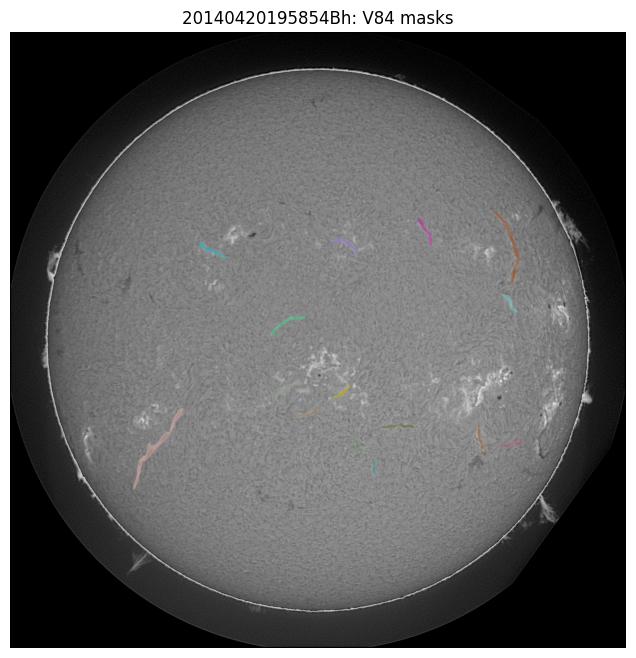

In [6]:
import cv2
import matplotlib.pyplot as plt

df = pd.read_csv(runs["v84"][0], dtype=str)
stem = df.filament_id.str.rsplit("_", n=1).str[0].value_counts().index[0]
img = cv2.imread(str(TEST_DIR / f"{stem}.jpeg"), cv2.IMREAD_GRAYSCALE)
overlay = np.dstack([img] * 3).astype(float) / 255
rng = np.random.default_rng(0)
for s in df[df.filament_id.str.startswith(stem + "_")].segmentation_rle:
    m = decode(s).astype(bool)
    overlay[m] = 0.5 * overlay[m] + 0.5 * rng.uniform(0.2, 1, 3)
plt.figure(figsize=(8, 8)); plt.imshow(overlay); plt.axis("off"); plt.title(f"{stem}: V84 masks"); plt.show()

## 5. Training (documented CLI, not run here)

The full training path (all-data detector, 5 OOF fold detectors, refiners, demote fit; many T4 GPU-hours) is in `README.md` §Training.
The weights in `weights/` are exactly the files those commands produced (hashes in `weights/SHA256SUMS`).